# NGC 4654 stellar mass and star-formation excess

This notebook uses the local 7000-run products and the SF selection from [the Paper II notebook](20261021_plot_paper_2.ipynb). The stellar-mass map shows finite, unmasked stellar-mass surface density with finite `SNR_POSTFIT > 25`. The excess map shows only selected SF spaxels, with the same sky coordinates and field of view as the mass map.

The [VIVA atlas](https://doi.org/10.1088/0004-6256/138/6/1741) describes compressed H I contours on the NW side and an extended H I tail to the SE. Colored boundary lines mark the two broad sky quadrants. Position angle is measured east of north from the Paper II photometric center. The NW wedge spans 270°–360° and the SE wedge spans 90°–180°.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.wcs import WCS
from IPython.display import display

PROJECT_ROOT = Path('/Users/Igniz/Desktop/ICRAR/further')
DATA_ROOT = PROJECT_ROOT / 'v3tk_v7.6.8_7000'

SNR_POSTFIT_MIN = 25.0  # STRICT common cut before any local SF/NSF/ND classification
INCLINATION_MAX = 80.0  # STRICT galaxy cut for the entire notebook
GEOMETRY_PATH = PROJECT_ROOT / 'MAUVE_effective_radii.csv'
CATALOG_PATH = PROJECT_ROOT / 'mauve_master_wiki_newclass.fits'
PAIR_PRODUCT_ID = 'NGC4567_8'
PAIR_SEGMENTATION_PATH = PROJECT_ROOT / 'NGC4567_8_photometric_segmentation_7000.fits'
PAIR_COMPONENT_LABELS = {'NGC4567': 1, 'NGC4568': 2}
STAGE_LABELS = {1:'Pre-peak',2:'Close-to-peak',3:'Post-peak'}
STAGE_COLORS = {1:'#2166ac',2:'#1a9850',3:'#d73027'}

# Use the same palette for every plot that identifies individual galaxies.
GALAXY_COLORS = {}
for palette_line in (PROJECT_ROOT / 'MAUVE_galaxy_colors.dat').read_text().splitlines():
    if not palette_line.strip() or palette_line.lstrip().startswith('#'):
        continue
    fields = palette_line.split()
    if fields[1] != 'TOTAL_ASSEMBLED':
        GALAXY_COLORS[fields[1]] = fields[3]

EW_MIN = 6.0
SIGMA_MAX = 45.0  # intrinsic Halpha sigma; strict upper bound

from matplotlib.lines import Line2D
from matplotlib.ticker import StrMethodFormatter

GALAXY = 'NGC4654'
SECTORS = {
    'NW compressed': (270, 360, '#d000a8'),
    'SE extended': (90, 180, '#00b9d0'),
}
excess_thresholds = np.arange(1, 4.5, 0.5)

mpl.rcParams.update({'font.size': 11, 'figure.dpi': 120})


## Load the Paper II SF sample

In [2]:
def first_existing(folder, names):
    for name in names:
        for p in (folder / name, folder / (name + '.gz')):
            if p.is_file():
                return p
    return None

def first_product_existing(product_id, names):
    for folder_suffix in ('', '_SFH16'):
        folder = DATA_ROOT / f'{product_id}{folder_suffix}'
        prefixes = (product_id, f'{product_id}{folder_suffix}')
        candidates = [f'{prefix}_{name}' for prefix in prefixes for name in names]
        found = first_existing(folder, candidates)
        if found is not None:
            return found
    return None

def read_map(path, name):
    with fits.open(path, memmap=True) as h:
        return np.array(h[name].data, dtype=float), h[name].header.copy()

def check_wcs(reference, other, shape, label):
    a, b = WCS(reference).celestial, WCS(other).celestial
    if not (a.has_celestial and b.has_celestial):
        raise ValueError(f'{label}: missing celestial WCS')
    ny, nx = shape
    x, y = np.array([0, nx-1, 0, nx-1, (nx-1)/2]), np.array([0, 0, ny-1, ny-1, (ny-1)/2])
    sep = a.pixel_to_world(x, y).separation(b.pixel_to_world(x, y)).arcsec
    if not np.isfinite(sep).all() or sep.max() > 0.05:
        raise ValueError(f'{label}: WCS separation {sep} arcsec')

def tangent_offsets_arcsec(ra_deg, dec_deg, ra0_deg, dec0_deg):
    ra, dec = np.deg2rad(ra_deg), np.deg2rad(dec_deg)
    ra0, dec0 = np.deg2rad(float(ra0_deg)), np.deg2rad(float(dec0_deg))
    dra = (ra - ra0 + np.pi) % (2 * np.pi) - np.pi
    cosc = np.sin(dec0) * np.sin(dec) + np.cos(dec0) * np.cos(dec) * np.cos(dra)
    with np.errstate(divide="ignore", invalid="ignore"):
        east = np.cos(dec) * np.sin(dra) / cosc
        north = (np.cos(dec0) * np.sin(dec) - np.sin(dec0) * np.cos(dec) * np.cos(dra)) / cosc
    return east * 206264.806247, north * 206264.806247

def galaxy_footprint(product_id, galaxy, shape, header):
    if product_id != PAIR_PRODUCT_ID:
        return True
    labels, label_header = read_map(PAIR_SEGMENTATION_PATH, 0)
    if labels.shape != shape:
        raise ValueError(f'{PAIR_PRODUCT_ID}: segmentation and science-map shapes differ')
    check_wcs(header, label_header, shape, f'{PAIR_PRODUCT_ID} mass/segmentation')
    if not np.all(np.isnan(labels) | np.isin(labels, (0, *PAIR_COMPONENT_LABELS.values()))):
        raise ValueError(f'{PAIR_SEGMENTATION_PATH}: unexpected segmentation labels')
    return labels == PAIR_COMPONENT_LABELS[galaxy]


def apply_component_inclination(product_id, component, mass, gas_arrays):
    if product_id != PAIR_PRODUCT_ID:
        return 0.0
    # The current combined products store projected densities (b/a = 1).
    q0 = float(component.intrinsic_axis_ratio_q0)
    cos_i = np.cos(np.deg2rad(float(component.inclination_deg)))
    b_over_a = np.sqrt((1 - q0**2) * cos_i**2 + q0**2)
    delta = float(np.log10(b_over_a))
    mass += delta
    for name in ('LOGSFR_SURFACE_DENSITY', 'LOGSFR_SURFACE_DENSITY_HII',
                 'LOGSFR_SURFACE_DENSITY_UPPER'):
        gas_arrays[name] += delta
    return delta


# The product ID locates FITS files; the galaxy ID determines geometry and statistics.
geometry = pd.read_csv(GEOMETRY_PATH)
with fits.open(CATALOG_PATH) as h:
    master_stage = {str(row['Galaxy']).strip(): int(row['class']) for row in h[1].data}
geometry['stage_code'] = geometry.galaxy.map(master_stage)
assert geometry.stage_code.notna().all(), 'Missing master stage for a geometry component'
assert np.array_equal(geometry.stage_code.astype(int), geometry.mauve_infall_stage.astype(int))
geometry_by_galaxy = geometry.set_index('galaxy', verify_integrity=True)
product_components = {
    product_id: tuple(components.galaxy)
    for product_id, components in geometry.groupby('notebook_product_id')
}


def iter_galaxy_inputs():
    product_ids = sorted({
        folder.name.removesuffix('_SFH16')
        for folder in DATA_ROOT.iterdir()
        if folder.is_dir() and not folder.name.endswith('_logs')
    })
    for product_id in product_ids:
        components = product_components[product_id]
        expected = set(PAIR_COMPONENT_LABELS) if product_id == PAIR_PRODUCT_ID else {product_id}
        if set(components) != expected:
            raise ValueError(f'{product_id}: unexpected geometry components {components}')
        paths = {
            'mass': first_product_existing(product_id, ['spatial_binning_maps_further.fits',
                                                        'SPATIAL_BINNING_maps_further.fits']),
            'gas': first_product_existing(product_id, ['gas_bin_maps_further.fits',
                                                       'gas_BIN_maps_further.fits']),
            'ew': first_product_existing(product_id, ['proxy_EW_maps_further.fits',
                                                      'proxy_EW_maps.fits']),
            'sfh': first_product_existing(product_id, ['sfh_maps.fits']),
            'mask': first_product_existing(product_id, ['mask.fits']),
        }
        for galaxy in sorted(components):
            component = geometry_by_galaxy.loc[galaxy]
            inclination = float(component.inclination_deg)
            meta = dict(stage=int(component.stage_code), inclination=inclination,
                        inclination_ok=bool(np.isfinite(inclination) and inclination < INCLINATION_MAX))
            yield product_id, galaxy, component, meta, paths




In [3]:
# Keep the mass/SFR selection and product inventory used for the Paper II excess curves.
sf_x_parts, sf_y_parts, sf_error_parts, sf_group_parts = [], [], [], []
count_rows = []
for product_id, gal, component, meta, paths in iter_galaxy_inputs():
    if meta['stage'] not in (1, 2) or not meta['inclination_ok'] or any(p is None for p in paths.values()):
        continue
    mass, mass_hdr = read_map(paths['mass'], 'LOGMASS_SURFACE_DENSITY')
    ew, ew_hdr = read_map(paths['ew'], 'PROXY_EWHA')
    snr_postfit, snr_hdr = read_map(paths['sfh'], 'SNR_POSTFIT')
    with fits.open(paths['gas'], memmap=True) as h:
        hdr = h[0].header.copy()
        gas_hdr = h['BIN_ID'].header.copy()
        arrays = {name: np.array(h[name].data, dtype=float) for name in (
            'BIN_ID', 'LOGSFR_SURFACE_DENSITY_HII', 'LOGSFR_SURFACE_DENSITY_UPPER',
            'LOGSFR_SURFACE_DENSITY', 'HA6562_SIGMA', 'HA6562_SIGMA_CORR',
            'HA6562_FLUX', 'HA6562_FLUX_ERR', 'HB4861_FLUX', 'HB4861_FLUX_ERR',
            'HA6562_FLUX_CORR', 'HA6562_FLUX_ERR_CORR')}
    if any(a.shape != mass.shape for a in [ew, snr_postfit, *arrays.values()]):
        raise ValueError(f'{gal}: map shape mismatch; align explicitly before using')
    check_wcs(mass_hdr, gas_hdr, mass.shape, gal+' mass/gas')
    check_wcs(mass_hdr, ew_hdr, mass.shape, gal+' mass/EW')
    check_wcs(mass_hdr, snr_hdr, mass.shape, gal+' mass/SFH SNR')
    with fits.open(paths['mask']) as h:
        flat_mask = np.asarray(h['MASKFILE'].data['MASK'])
        if flat_mask.size != mass.size:
            raise ValueError(f'{gal}: spatial mask length mismatch')
        spatial_mask = flat_mask.reshape(mass.shape)
    apply_component_inclination(product_id, component, mass, arrays)
    # Mandatory first-stage usability gate: only then define SF, ND, or remaining NSF.
    footprint = galaxy_footprint(product_id, gal, mass.shape, mass_hdr)
    pre_snr = np.isfinite(mass) & np.isfinite(arrays['BIN_ID']) & (spatial_mask == 0) & footprint
    snr_pass = np.isfinite(snr_postfit) & (snr_postfit > SNR_POSTFIT_MIN)
    valid = pre_snr & snr_pass
    assert np.all(snr_postfit[valid] > 25.0)
    assert not np.any(valid & (~np.isfinite(snr_postfit) | (snr_postfit <= 25.0)))
    sn_cut, floor = float(hdr['CUT_SN']), float(hdr['NOISE'])
    assert np.isfinite(sn_cut) and sn_cut > 0 and np.isfinite(floor) and floor > 0
    assert str(hdr['BPTMODE']).lower().strip() == 'both', f'{gal}: unexpected BPTMODE'
    balmer = np.ones(mass.shape, dtype=bool)
    for line in ('HA6562', 'HB4861'):
        f, e = arrays[line+'_FLUX'], arrays[line+'_FLUX_ERR']
        good = np.isfinite(f) & np.isfinite(e) & (e > 0)
        with np.errstate(divide='ignore', invalid='ignore'):
            balmer &= good & (f/e >= sn_cut) & (f >= floor)
    sigma2 = arrays['HA6562_SIGMA']**2 - arrays['HA6562_SIGMA_CORR']**2
    sigma = np.sqrt(np.where(np.isfinite(sigma2) & (sigma2 > 0), sigma2, np.nan))
    sfr = arrays['LOGSFR_SURFACE_DENSITY_HII']
    sf = valid & np.isfinite(sfr) & np.isfinite(ew) & (ew > EW_MIN) & np.isfinite(sigma) & (sigma < SIGMA_MAX)
    nd = valid & ~balmer
    nd_upper = arrays['LOGSFR_SURFACE_DENSITY_UPPER']
    assert np.isfinite(nd_upper[nd]).all(), f'{gal}: missing ND SFR upper limits'
    assert np.allclose(nd_upper[nd], arrays['LOGSFR_SURFACE_DENSITY'][nd]), f'{gal}: ND SFR map mismatch'
    assert not np.any(sf & nd), f'{gal}: SF overlaps Balmer ND'
    assert np.all(snr_postfit[sf | nd] > 25.0), f'{gal}: category bypassed strict SNR cut'

    group_id = len(count_rows)
    sf_x_parts.append(mass[sf])
    sf_y_parts.append(sfr[sf])
    sf_group_parts.append(np.full(sf.sum(), group_id, dtype=int))
    count_rows.append(dict(galaxy=gal, stage=meta['stage'], SF=int(sf.sum())))
    # Paired Halpha errors for the source excess-width recipe, in the same SF order.
    ha_flux_sf = arrays['HA6562_FLUX_CORR'][sf]
    ha_error_sf = arrays['HA6562_FLUX_ERR_CORR'][sf]
    ha_error_ok = np.isfinite(ha_flux_sf) & (ha_flux_sf > 0) & np.isfinite(ha_error_sf) & (ha_error_sf >= 0)
    sf_error_dex = np.full(len(ha_flux_sf), np.nan)
    sf_error_dex[ha_error_ok] = ha_error_sf[ha_error_ok] / ha_flux_sf[ha_error_ok] / np.log(10.0)
    sf_error_parts.append(sf_error_dex)

    if gal == GALAXY:
        focal_mass = np.where((spatial_mask == 0) & np.isfinite(mass), mass, np.nan)
        focal_snr_pass = snr_pass.copy()
        focal_wcs = WCS(mass_hdr).celestial
        focal_sf = sf.copy()

excess_meta = pd.DataFrame(count_rows)
if GALAXY not in excess_meta.galaxy.values:
    raise ValueError(f'{GALAXY}: no eligible Paper II products')
focal_group = excess_meta.index[excess_meta.galaxy.eq(GALAXY)].item()
if excess_meta.loc[focal_group, 'stage'] != 2 or not focal_sf.any():
    raise ValueError(f'{GALAXY}: expected selected SF spaxels in the close-to-peak stage')
sf_x = np.concatenate(sf_x_parts)
sf_y = np.concatenate(sf_y_parts)
sf_group = np.concatenate(sf_group_parts)


## Pre-peak reference and NGC 4654 maps

Each pre-peak galaxy contributes unit total weight to the OLS reference. The Paper II width \(W\) is the equal-galaxy mean of each galaxy's mean error-corrected absolute residual, \(\sqrt{\max(\Delta^2-\sigma_{\log\Sigma_{\rm SFR}}^2,0)}\). The plotted excess is \(E=\Delta/W\).

In [4]:
def equal_galaxy_ols(x, y, group):
    """Minimize sum_g mean_g[(y-alpha*x-beta)**2]; weight per pixel = 1/N_g."""
    x, y, group = np.asarray(x), np.asarray(y), np.asarray(group)
    assert len(x) == len(y) == len(group) and len(x) > 2
    assert np.isfinite(x).all() and np.isfinite(y).all() and (group >= 0).all()
    # Exact weighted moments; no per-spaxel design matrix or variance weighting.
    count = np.bincount(group)
    active = count > 0
    gx = np.bincount(group,weights=x)[active]/count[active]
    gy = np.bincount(group,weights=y)[active]/count[active]
    gxx = np.bincount(group,weights=x*x)[active]/count[active]
    gxy = np.bincount(group,weights=x*y)[active]/count[active]
    mx, my = gx.mean(), gy.mean()
    variance_x = gxx.mean()-mx**2
    assert variance_x > 0
    slope = (gxy.mean()-mx*my)/variance_x
    intercept = my-slope*mx
    # Weighted residual normal equations must vanish for the OLS solution.
    assert np.isclose((gy-slope*gx-intercept).mean(),0,atol=1e-9)
    assert np.isclose((gxy-slope*gxx-intercept*gx).mean(),0,atol=1e-8)
    return dict(slope=float(slope),intercept=float(intercept),n_spaxels=len(x),
        n_groups=int(active.sum()),xmin=float(x.min()),xmax=float(x.max()),
        group_ids=np.flatnonzero(active),group_counts=count[active])


pre_peak = excess_meta.stage.to_numpy()[sf_group] == 1
pre_peak_fit = equal_galaxy_ols(sf_x[pre_peak], sf_y[pre_peak], sf_group[pre_peak])
excess_errors = np.concatenate(sf_error_parts)
assert len(excess_errors) == len(sf_x) == len(sf_y) == len(sf_group)
excess_reference = pre_peak_fit['slope'] * sf_x + pre_peak_fit['intercept']
excess_residuals = sf_y - excess_reference
excess_pre_ids = excess_meta.index[(excess_meta.stage == 1) & (excess_meta.SF > 0)].to_numpy()
assert len(excess_pre_ids), 'No pre-peak SF reference products'
excess_width_rows = []
for group_id in excess_pre_ids:
    selected = (sf_group == group_id) & np.isfinite(excess_errors) & (excess_errors >= 0)
    assert selected.any(), f'{excess_meta.loc[group_id, "galaxy"]}: no finite errors for width'
    radicand = excess_residuals[selected]**2 - excess_errors[selected]**2
    excess_width_rows.append(dict(galaxy=excess_meta.loc[group_id, 'galaxy'],
        N_width=int(selected.sum()), width_dex=float(np.sqrt(np.maximum(radicand, 0)).mean()),
        fraction_clipped_to_zero=float((radicand <= 0).mean())))
excess_width_by_galaxy = pd.DataFrame(excess_width_rows)
excess_width = float(excess_width_by_galaxy.width_dex.mean())
assert np.isfinite(excess_width) and excess_width > 0
excess_values = excess_residuals / excess_width

focal_values = excess_values[sf_group == focal_group]
focal_excess = np.full(focal_sf.shape, np.nan)
focal_excess[focal_sf] = focal_values

center = geometry_by_galaxy.loc[GALAXY]
def sky_offsets(x, y):
    ra, dec = focal_wcs.pixel_to_world_values(x, y)
    return tangent_offsets_arcsec(ra, dec, center.center_ra_deg, center.center_dec_deg)

y_sf, x_sf = np.nonzero(focal_sf)
sf_east, sf_north = sky_offsets(x_sf, y_sf)
sf_pa = np.degrees(np.arctan2(sf_east, sf_north)) % 360
has_direction = np.hypot(sf_east, sf_north) > 0
sector_masks = {
    label: has_direction & (sf_pa >= lo) & (sf_pa < hi)
    for label, (lo, hi, _) in SECTORS.items()
}

print(f'Pre-peak reference: y = {pre_peak_fit["slope"]:.4f}x '
      f'{pre_peak_fit["intercept"]:+.4f}; W = {excess_width:.4f} dex')


Pre-peak reference: y = 0.7483x -7.9923; W = 0.3915 dex


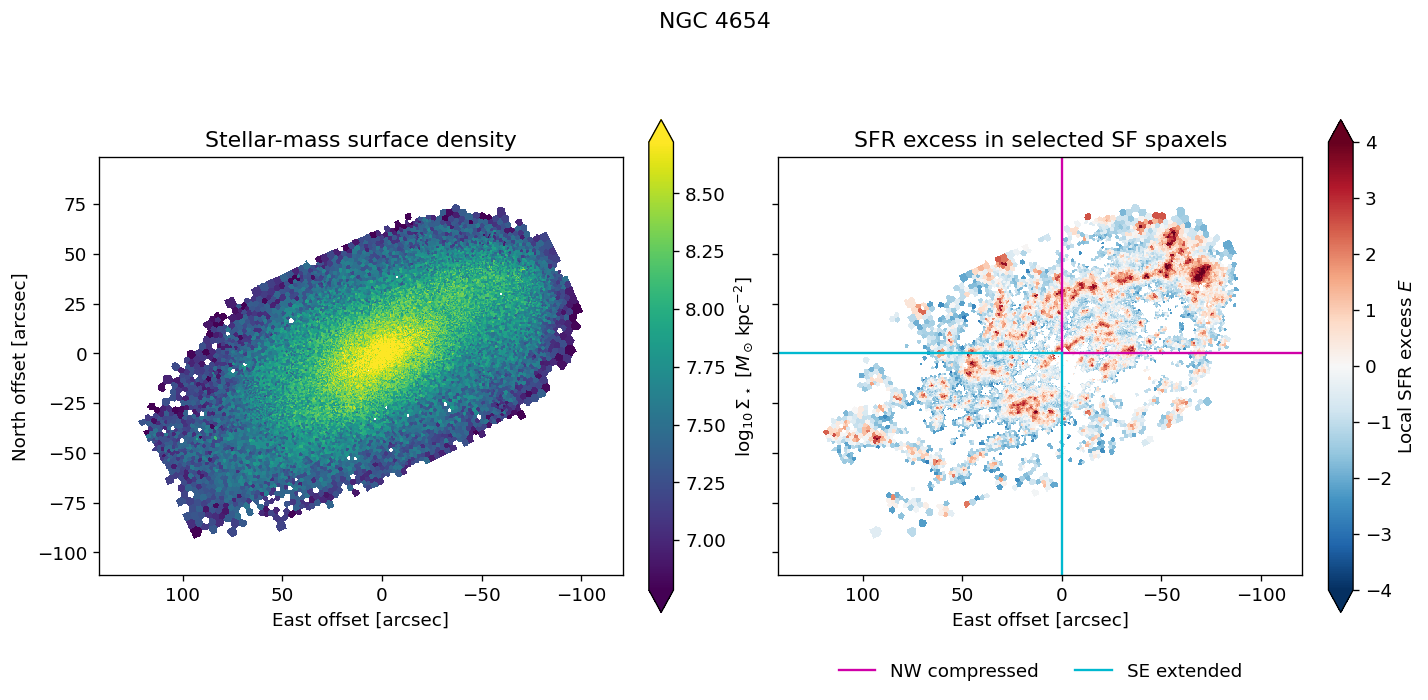

In [5]:
ny, nx = focal_mass.shape
edge_x, edge_y = np.meshgrid(np.arange(nx + 1) - 0.5, np.arange(ny + 1) - 0.5)
east_edges, north_edges = sky_offsets(edge_x, edge_y)
mass_y, mass_x = np.nonzero(np.isfinite(focal_mass))
east_mass, north_mass = sky_offsets(mass_x, mass_y)

def limits(values):
    return values.min() - 4, values.max() + 4

east_limits = limits(east_mass)
north_limits = limits(north_mass)
fig_maps, (ax_mass, ax_excess) = plt.subplots(
    1, 2, figsize=(11.8, 5.8), sharex=True, sharey=True, layout='constrained'
)
stellar_mass_map = np.where(focal_snr_pass, focal_mass, np.nan)
mass_lo, mass_hi = np.nanpercentile(stellar_mass_map, [1, 99])
mass_image = ax_mass.pcolormesh(
    east_edges, north_edges, stellar_mass_map, shading='flat', cmap='viridis',
    vmin=mass_lo, vmax=mass_hi, rasterized=True,
)
excess_image = ax_excess.pcolormesh(
    east_edges, north_edges, focal_excess, shading='flat', cmap='RdBu_r',
    vmin=-4, vmax=4, rasterized=True,
)
fig_maps.colorbar(mass_image, ax=ax_mass, shrink=0.76, extend='both',
    label=r'$\log_{10}\Sigma_\star$ [$M_\odot\,\mathrm{kpc}^{-2}$]')
fig_maps.colorbar(excess_image, ax=ax_excess, shrink=0.76, extend='both',
    label=r'Local SFR excess $E$')

# Extend the boundary rays past the map edge so they span the plotted field.
line_radius = 1.1 * np.hypot(max(map(abs, east_limits)), max(map(abs, north_limits)))
sector_handles = []
for label, (lo, hi, color) in SECTORS.items():
    for boundary in np.radians([lo, hi]):
        ax_excess.plot([0, line_radius * np.sin(boundary)],
            [0, line_radius * np.cos(boundary)], color=color, lw=1.4)
    sector_handles.append(Line2D([], [], color=color, lw=1.4, label=label))
ax_excess.legend(handles=sector_handles, loc='upper center', ncol=2,
    bbox_to_anchor=(0.5, -0.17), frameon=False)

for ax in (ax_mass, ax_excess):
    ax.set(aspect='equal', xlim=east_limits[::-1], ylim=north_limits,
        xlabel='East offset [arcsec]')
ax_mass.set(ylabel='North offset [arcsec]', title='Stellar-mass surface density')
ax_excess.set_title('SFR excess in selected SF spaxels')
fig_maps.suptitle('NGC 4654')
plt.show()


## Fraction of selected SF spaxels above the excess threshold

For each threshold \(t\), the fraction is \(N_{\rm SF}(E>t)/N_{\rm SF}\), computed separately for the whole galaxy and for each colored sector. The stage curves give equal weight to each galaxy with selected SF spaxels. NGC 4654 is included in the close-to-peak mean, as in Paper II. The pre-peak band spans the 16th–84th percentiles of the individual pre-peak galaxy fractions. The log axis leaves bins with zero exceedances unplotted. The table retains their counts.

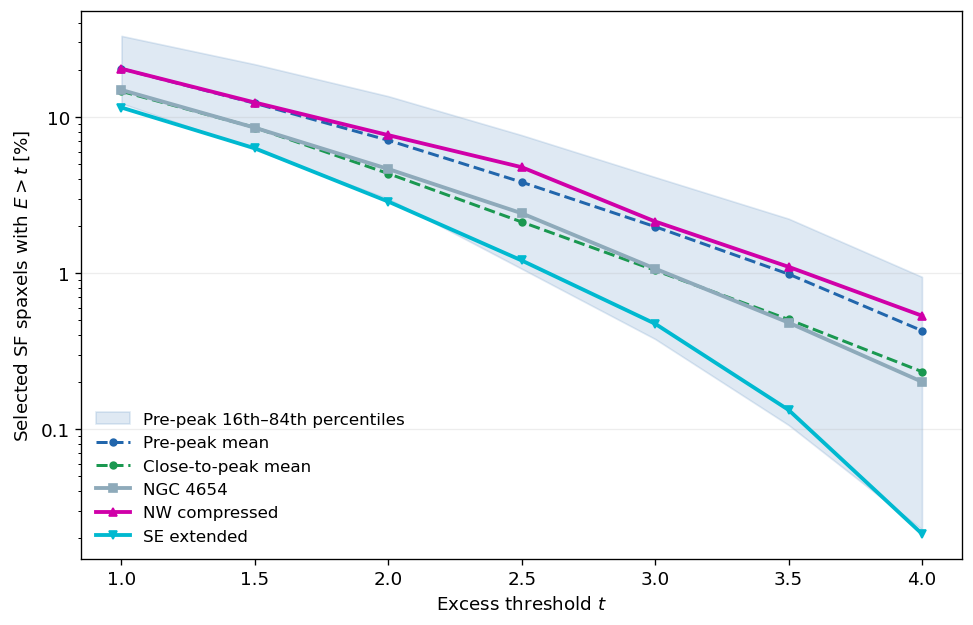

E threshold,Selected SF total,1.0,1.5,2.0,2.5,3.0,3.5,4.0
NGC4654,325678,48496,27774,15100,7858,3471,1566,654
NW compressed,117266,23869,14500,8961,5584,2506,1284,624
SE extended,107865,12385,6785,3093,1297,510,143,23


In [6]:
def tail_counts(values):
    # Strict inequality and the same thresholds as the Paper II curves.
    return np.count_nonzero(values[:, None] > excess_thresholds, axis=0)

galaxy_tails = {
    record.galaxy: tail_counts(excess_values[sf_group == group_id]) / record.SF
    for group_id, record in excess_meta.iterrows() if record.SF > 0
}
stage_tails = {
    stage: np.stack([galaxy_tails[gal] for gal in excess_meta.loc[
        excess_meta.stage.eq(stage) & excess_meta.SF.gt(0), 'galaxy']])
    for stage in (1, 2)
}
stage_means = {stage: tails.mean(axis=0) for stage, tails in stage_tails.items()}
pre_bounds = np.quantile(stage_tails[1], [0.16, 0.84], axis=0)

region_values = {GALAXY: focal_values}
region_values.update({label: focal_values[mask] for label, mask in sector_masks.items()})
if any(values.size == 0 for values in region_values.values()):
    raise ValueError('Every plotted NGC 4654 region needs selected SF spaxels.')
region_counts = {label: tail_counts(values) for label, values in region_values.items()}
region_fractions = {
    label: region_counts[label] / values.size for label, values in region_values.items()
}
assert np.allclose(region_fractions[GALAXY], galaxy_tails[GALAXY])
assert not np.any(sector_masks['NW compressed'] & sector_masks['SE extended'])

fig_fraction, ax = plt.subplots(figsize=(8.0, 5.1), layout='constrained')
ax.fill_between(excess_thresholds, 100 * pre_bounds[0], 100 * pre_bounds[1],
    where=pre_bounds[0] > 0, color=STAGE_COLORS[1], alpha=0.14,
    label='Pre-peak 16th–84th percentiles')
for stage in (1, 2):
    ax.plot(excess_thresholds, 100 * stage_means[stage], 'o--', lw=1.8, ms=4,
        color=STAGE_COLORS[stage], label=f'{STAGE_LABELS[stage]} mean')
region_colors = {
    GALAXY: GALAXY_COLORS[GALAXY],
    **{label: color for label, (_, _, color) in SECTORS.items()},
}
for (label, fraction), marker in zip(region_fractions.items(), ('s', '^', 'v')):
    ax.plot(excess_thresholds, 100 * fraction, marker=marker, ms=5, lw=2.3,
        color=region_colors[label], label='NGC 4654' if label == GALAXY else label)
ax.set(xticks=excess_thresholds, xlabel=r'Excess threshold $t$',
    ylabel='Selected SF spaxels with $E>t$ [%]')
ax.set_yscale('log', nonpositive='mask')
ax.yaxis.set_major_formatter(StrMethodFormatter('{x:g}'))
ax.grid(axis='y', alpha=0.22)
ax.legend(loc='lower left', frameon=False, fontsize=10)
plt.show()

support = pd.DataFrame(region_counts, index=pd.Index(excess_thresholds, name='E threshold')).T
support.insert(0, 'Selected SF total', [values.size for values in region_values.values()])
display(support)
